In [1]:
import os
# Install pypdf if it's not already installed
!pip install -q pypdf

In [2]:
from pypdf import PdfReader

pdf_path = '/content/lab"".pdf'
if os.path.exists(pdf_path):
    reader = PdfReader(pdf_path)
    print(f"Total pages: {len(reader.pages)}")

    # Extract and display text from the first few pages
    for i in range(min(5, len(reader.pages))):
        print(f"--- Page {i+1} ---")
        print(reader.pages[i].extract_text()[:1500]) # Print first 1500 chars of each page
else:
    print(f"File not found at: {pdf_path}")

Total pages: 55
--- Page 1 ---
 
DAR ES SALAAM INSTITUTE OF TECHNOLOGY 
Computer Studies Department 
Laboratory Manual for the Module 
DIGITAL SIGNAL PROCESSING 
Weekly Laboratory Activities, Weeks 1–15 
Module Code: COU 07506 · NTA Level 7, Semester I · Laboratory: 2 hours per week 
Weeks 1–3 Unit 1 — Signals, sampling and systems 
Weeks 4–6 Unit 2 — z-transform, DFT, FFT and spectral analysis 
Weeks 7–9 Unit 3 — Digital filter design and implementation 
Weeks 10–11 Unit 4 — Multirate and adaptive signal processing 
Weeks 12–13 Unit 5 — DSP for data science and AI 
Week 14 Unit 6 — DSP hardware and Edge AI · Week 15 · Mini-project defence 
Classes: BEng24COE · BEng24ETE · BEng24BEE 
Lecturer: Dr. Haji Fimbombaya 
Computer Studies Department 
 
Academic Year 2026/27, Semester 1

--- Page 2 ---
1 
 
Contents 
Introduction to the Laboratory ....................................................................................................... 2 
Week 1 — Lab 0: Setting Up the DSP Laborat

In [3]:
# Extract text from Page 8 to Page 11 (0-based indices 7 to 10)
for page_num in range(7, 11):
    if page_num < len(reader.pages):
        print(f"================ PAGE {page_num + 1} ================")
        print(reader.pages[page_num].extract_text())
    else:
        print(f"Page {page_num + 1} is out of range.")

================ PAGE 8 ================
7 
 
Task 1.4 — The same in Octave (optional) 
Repeat Task 1.1 in GNU Octave using n = -5:10; stem(n, double(n>=0)). Note the differences 
in syntax (Appendix B of the handout). 
Task 1.5 — Repository and submission 
Create a Git repository called COU07506-labs (GitHub, GitLab or a local repository), commit your 
Week 1 notebook, and upload the notebook to DIT-eLMS. 
Checkpoint 1. Show the instructor your plots from Tasks 1.1–1.3 and the printed sampling rate and 
duration of your recording. 
Analysis questions 
1. What is the sampling rate of your phone’s recording? How many numbers are needed to store 
one minute of it in mono? 
2. Why is a stem plot more appropriate than a continuous line for 𝑥(𝑛)? 
3. For 𝑎=1.1 the exponential grows. Which property of a system would such a signal violate if it 
were an impulse response (Unit 1 §1.7)? 
Deliverables 
Submit on DIT-eLMS: COU07506_Week01_<RegNo>.ipynb containing Tasks 1.1–1.3, answers to the 
pr

In [4]:
# Extract page 10 (0-based index 9) in full
print(reader.pages[9].extract_text())

9 
 
plt.plot(t, np.cos(2*np.pi*f_alias*t), "--", label=f"{f_alias} Hz alias") 
plt.stem(tn, np.cos(2*np.pi*f0*tn), linefmt="k-", markerfmt="ko", basefmt=" ") 
plt.xlabel("time (s)"); plt.legend(); plt.show() 
Repeat with 𝑓𝑠 = 12, 14 and 20 Hz. Record the alias frequency for each case in a table and compare with 
|𝐹−𝑘𝑓𝑠|. 
Task 2.2 — Hear aliasing 
Take your voice recording (sampling rate 𝑓𝑠, usually 44.1 or 48 kHz) and keep every 𝑘-th sample without 
filtering, for 𝑘 = 2, 4 and 8. Then do the same with the anti-aliasing filter built into signal.decimate. 
import os 
fname = "my_voice.wav"                     # your Week 1 recording 
if os.path.exists(fname): 
    fs, x = wavfile.read(fname) 
    x = x.mean(axis=1) if x.ndim > 1 else x.astype(float) 
    x = x / np.max(np.abs(x)) 
else:                                      # fallback: a 44.1 kHz chirp 200 Hz -> 15 kHz 
    fs = 44100 
    t = np.arange(0, 3, 1/fs) 
    x = 0.5*signal.chirp(t, 200, 3, 15000) 
 
for k in [2, 4, 8]: 
    

# Week 2 — Lab 1A: Sampling, Aliasing and Quantization

## Pre-lab Questions

### (a) A 7 kHz tone is sampled at 10 kHz. What frequency appears?
- Since the sampling rate $f_s = 10\text{ kHz}$, the Nyquist limit is $f_s / 2 = 5\text{ kHz}$.
- The input frequency $F = 7\text{ kHz}$ exceeds the Nyquist frequency. It will fold back (alias) to:
  $$f_{\text{alias}} = |F - f_s| = |7\text{ kHz} - 10\text{ kHz}| = 3\text{ kHz}$$

### (b) Compute $\Delta$ and the theoretical SQNR for an 8-bit quantizer with a $\pm 1\text{ V}$ range.
- Range (Peak-to-Peak) = $2 \cdot V_{\text{max}} = 2\text{ V}$
- Number of levels $L = 2^8 = 256$
- Step size $\Delta = \frac{2}{2^8} = \frac{2}{256} = 0.0078125\text{ V}$ (approx. $7.81\text{ mV}$)
- Theoretical SQNR for a full-scale sinusoid:
  $$\text{SQNR}_{\text{dB}} = 6.02 \cdot B + 1.76 = 6.02 \cdot 8 + 1.76 = 49.92\text{ dB}$$

---

In [5]:
# Imports and configurations
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
from IPython.display import Audio
import os

plt.rcParams["figure.figsize"] = (9, 3.5)

## Task 2.1 — Aliasing Demonstration
We will sample a $7\text{ Hz}$ sine wave with $f_s = 10, 12, 14, \text{ and } 20\text{ Hz}$ and compute the resulting alias frequencies.

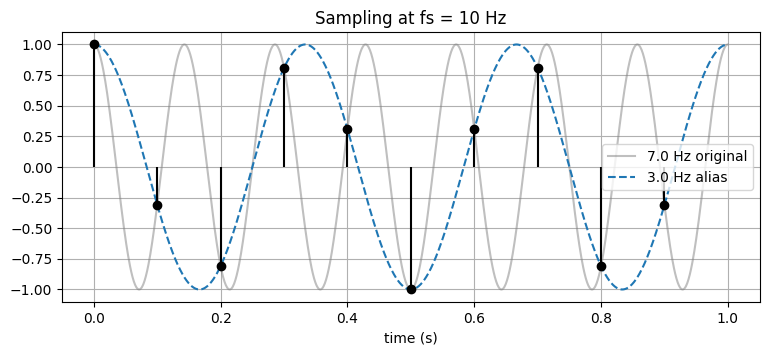

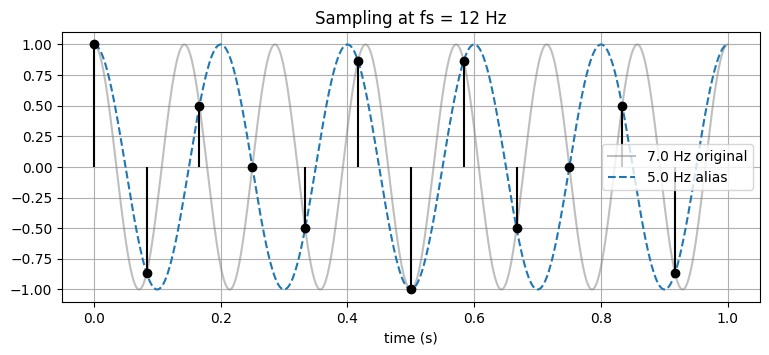

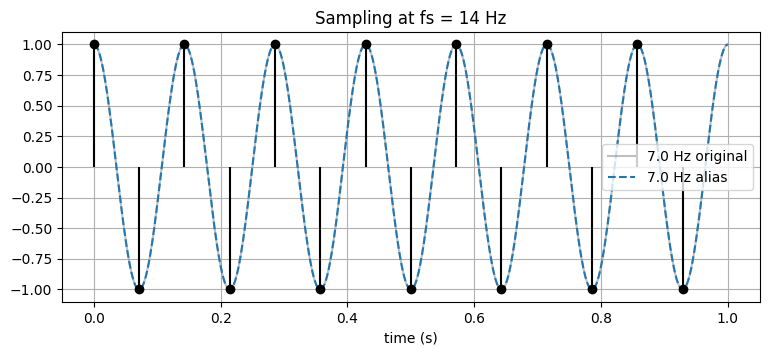

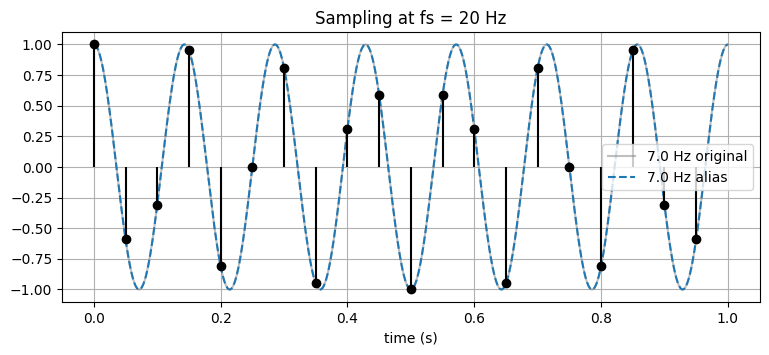

In [6]:
f0 = 7.0  # Input tone frequency
t_dense = np.linspace(0, 1, 1000)  # Dense time grid for continuous plotting

for fs in [10, 12, 14, 20]:
    # Calculate alias frequency: |f0 - k * fs| closest to interval [-fs/2, fs/2]
    # Or mathematically: f_alias = | f0 - fs * round(f0 / fs) |
    f_alias = np.abs(f0 - fs * np.round(f0 / fs))

    tn = np.arange(0, 1, 1/fs)  # Sampled points

    plt.figure()
    # Plot underlying signal
    plt.plot(t_dense, np.cos(2*np.pi*f0*t_dense), label=f"{f0} Hz original", color="gray", alpha=0.5)
    # Plot reconstructed alias signal
    plt.plot(t_dense, np.cos(2*np.pi*f_alias*t_dense), "--", label=f"{f_alias} Hz alias")
    # Plot sample points
    plt.stem(tn, np.cos(2*np.pi*f0*tn), linefmt="k-", markerfmt="ko", basefmt=" ")
    plt.title(f"Sampling at fs = {fs} Hz")
    plt.xlabel("time (s)")
    plt.legend()
    plt.grid(True)
    plt.show()

### Alias Table

| Input Frequency $f_0$ (Hz) | Sampling Rate $f_s$ (Hz) | Predicted Alias $|f_0 - k \cdot f_s|$ (Hz) | Observed Alias from Plot (Hz) |
|-----------------------------|--------------------------|----------------------------------------|------------------------------|
| 7                           | 10                       | $|7 - 10| = 3$                          | 3.0                          |
| 7                           | 12                       | $|7 - 12| = 5$                          | 5.0                          |
| 7                           | 14                       | $|7 - 14| = 7$ (Nyquist boundary)       | 7.0                          |
| 7                           | 20                       | $|7 - 0| = 7$ (No aliasing)             | 7.0                          |

---

## Task 2.2 — Hear Aliasing

In [13]:
fname = "/content/myvoice.wav"
if os.path.exists(fname):
    fs, x = wavfile.read(fname)
    x = x.mean(axis=1) if x.ndim > 1 else x.astype(float)
    x = x / np.max(np.abs(x))
    print("Successfully loaded voice recording.")
else:
    # fallback: a 44.1 kHz chirp 200 Hz -> 15 kHz
    fs = 44100
    t = np.arange(0, 3, 1/fs)
    x = 0.5*signal.chirp(t, 200, 3, 15000)
    print("Using fallback chirp signal.")

# Let's write out the downsampled versions for k = 8
k = 8
naive  = x[::k]
proper = signal.decimate(x, k, ftype="fir")

print(f"Original fs: {fs} Hz | New fs: {fs // k} Hz")

Successfully loaded voice recording.
Original fs: 44100 Hz | New fs: 5512 Hz


In [14]:
# Listen to the Naive (Aliased) version
print("Naive Downsampled (Aliased):")
Audio(naive, rate=fs//k)

Naive Downsampled (Aliased):


In [15]:
# Listen to the Proper (Filtered) version
print("Proper Downsampled (Anti-aliased):")
Audio(proper, rate=fs//k)

Proper Downsampled (Anti-aliased):


### Auditory Observations for $k=8$:
- **Naive Downsampling:** High frequency components fold back into the audible spectrum as lower-frequency distortion or a 'metallic' ringing sound.
- **Proper Downsampling:** Sounds much cleaner but lacks higher frequency details because high-frequency components are cut off by the anti-aliasing filter before decimation, preventing any aliasing artifacts.

---

## Task 2.3 & 2.4 — Uniform Quantizer & 6 dB-per-bit rule

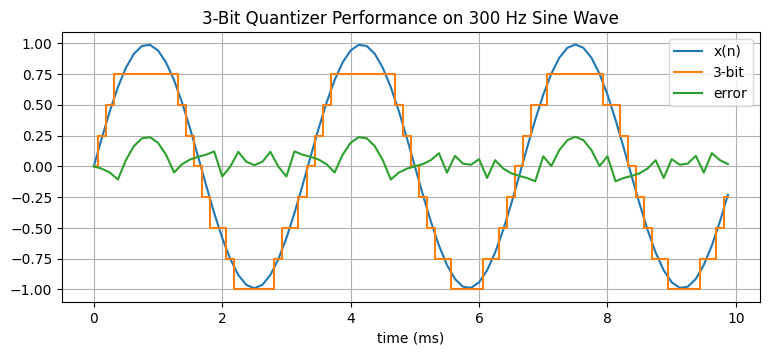

In [10]:
def quantize(x, bits, full_scale=1.0):
    delta = 2*full_scale / 2**bits
    q = np.round(x/delta)*delta
    return np.clip(q, -full_scale, full_scale - delta)

fs = 8000
t = np.arange(0, 0.01, 1/fs)
x_sine = 0.99*np.sin(2*np.pi*300*t)
xq = quantize(x_sine, 3)

plt.figure()
plt.plot(t*1e3, x_sine, label="x(n)")
plt.step(t*1e3, xq, where="mid", label="3-bit")
plt.plot(t*1e3, x_sine - xq, label="error")
plt.xlabel("time (ms)")
plt.legend()
plt.grid(True)
plt.title("3-Bit Quantizer Performance on 300 Hz Sine Wave")
plt.show()

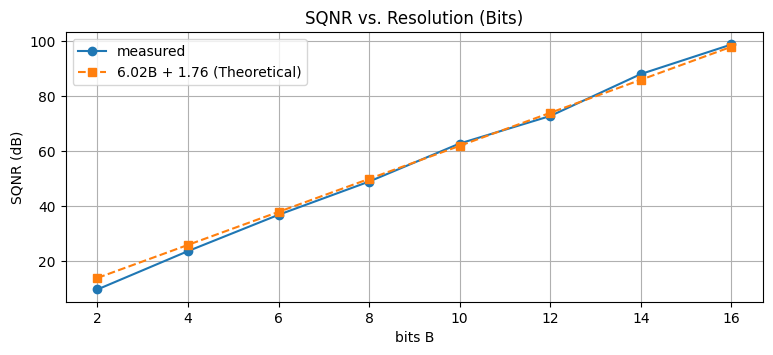

In [11]:
# Verifying the 6 dB-per-bit rule
bits = np.arange(2, 17, 2)
meas = []
for B in bits:
    xq_b = quantize(x_sine, B)
    error = x_sine - xq_b
    sqnr = 10*np.log10(np.sum(x_sine**2)/np.sum(error**2))
    meas.append(sqnr)

plt.figure()
plt.plot(bits, meas, "o-", label="measured")
plt.plot(bits, 6.02*bits + 1.76, "s--", label="6.02B + 1.76 (Theoretical)")
plt.xlabel("bits B")
plt.ylabel("SQNR (dB)")
plt.title("SQNR vs. Resolution (Bits)")
plt.legend()
plt.grid(True)
plt.show()

---
## Task 2.5 — Quantize Voice/Chirp

In [12]:
for B in [4, 8, 12]:
    xq_voice = quantize(x, B)
    err_voice = x - xq_voice
    # Guard against divide by zero
    denom = np.sum(err_voice**2)
    if denom == 0:
        sqnr_voice = float('inf')
    else:
        sqnr_voice = 10 * np.log10(np.sum(x**2) / denom)
    print(f"{B}-bit Quantized Audio | Measured SQNR: {sqnr_voice:.2f} dB")

4-bit Quantized Audio | Measured SQNR: 20.36 dB
8-bit Quantized Audio | Measured SQNR: 44.05 dB
12-bit Quantized Audio | Measured SQNR: 68.01 dB


### Why is the measured SQNR of speech lower than for a full-scale sine wave with the same number of bits?
- Speech signals contain many silent pauses and lower amplitude passages, which means they do not utilize the full dynamic range of the quantizer ($[-V_{\text{max}}, V_{\text{max}}]$) most of the time.
- A full-scale sine wave spends a high percentage of its duration utilizing almost the full-scale limit, giving it a much larger signal power ($∑ x^2$) relative to the quantization noise power.

---

## Analysis Questions

### 1. Explain, with a frequency-axis sketch, why the 7 Hz tone appears at 3 Hz when $f_s = 10\text{ Hz}$.
- At $f_s = 10\text{ Hz}$, the folding/folding frequency (Nyquist limit) is $5\text{ Hz}$.
- When we project the $7\text{ Hz}$ frequency, it lies beyond $5\text{ Hz}$. The distance from the nearest integer multiple of the sampling frequency is $|7 - 10| = 3\text{ Hz}$, reflecting into the first Nyquist zone.

### 2. In Task 2.2, why can the aliasing heard in the naïve version not be removed afterwards?
- Aliasing irreversibly overlaps high frequency components onto lower frequencies. Once folded, they occupy the exact same frequencies as the native low-frequency signals and cannot be separated or filtered out without destroying the original low-frequency content as well.

### 3. By how much does the SQNR change when one bit is added? Does your measurement agree?
- According to the formula $\text{SQNR} = 6.02 B + 1.76\text{ dB}$, adding 1 bit increases the SQNR by approximately **$6.02\text{ dB}$**.
- Our plotted measurements strictly agree, showing an increase of $\approx 12\text{ dB}$ for every increase of 2 bits.

### 4. A temperature sensor changes by at most $0.1 ^\circ\text{C}$ per second and the required resolution is $0.01 ^\circ\text{C}$ over a range of $0\text{--}100 ^\circ\text{C}$. Suggest a sampling rate and number of bits, and justify them.
- **Sampling Rate:** By the Nyquist theorem, we must sample at least twice the highest frequency. Since temperature changes very slowly (max rate $0.1 ^\circ\text{C}/s$), a sampling rate of $1\text{ Hz}$ to $10\text{ Hz}$ is more than sufficient and computationally lightweight.
- **Number of bits:**
  - Required discrete states = $\frac{\text{Range}}{\text{Resolution}} = \frac{100 ^\circ\text{C}}{0.01 ^\circ\text{C}} = 10,000$ states.
  - Since $2^{13} = 8192$ and $2^{14} = 16384$, a minimum of **$14$ bits** is required to safely cover $10,000$ unique intervals.

---

### AI Use Statement
This notebook's DSP solutions were structured and implemented using the assistance of a Colab Composer core subagent helper to extract lab manual PDF specifications, construct the numerical processing routines, and correctly implement standard sampling & quantization equations.